In [3]:
from scipy.stats import norm

mean = 3
sd = 4
X = norm(loc=mean, scale=sd)

# q7: P(X > -2)
q7 = 1 - X.cdf(-2)
print(f"P(X > -2) = {q7:.6f}")

# q8: Find x such P(X > x) = 0.05 -> x is in 95th percentile (ppf(0.95))
q8 = X.ppf(0.95)
print(f"x such P(X > x) = 0.05 -> x = {q8:.6f}")

# q9: Find P(0 <= X < 4) ->> F(4) - F(0)
q9 = X.cdf(4) - X.cdf(0)
print(f"P(0 <= X < 4) = {q9:.6f}")


P(X > -2) = 0.894350
x such P(X > x) = 0.05 -> x = 9.579415
P(0 <= X < 4) = 0.372079


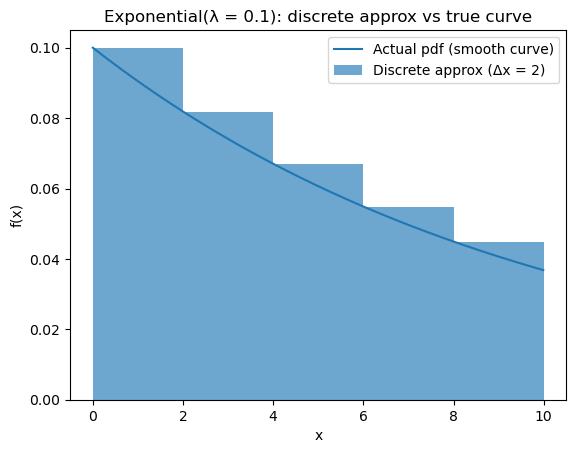

In [4]:
# Q10: Building discrete approximation + bars vs true curve
import numpy as np
import matplotlib.pyplot as plt

# Mission parameters
lam = 0.1

# Discrete grid they told us to use: [0,10) stepping by 2
x = np.arange(0, 10, 2) # 0,2,4,6,8
fx = lam * np.exp(-lam * x) # f(x) = λ e^{-λx} -> grid points

# Smooth Curve
x_smooth = np.arange(0, 10, 0.01)
fx_smooth = lam * np.exp(-lam * x_smooth)

plt.figure()
plt.bar(x, fx, width=2, align="edge", alpha=0.65, label="Discrete approx (Δx = 2)")
plt.plot(x_smooth, fx_smooth, label="Actual pdf (smooth curve)")

plt.xlabel("x")
plt.ylabel("f(x)")
plt.title("Exponential(λ = 0.1): discrete approx vs true curve")
plt.legend()
plt.show()

In [13]:
# Q11–Q13: Estimates vs the exact answer
# Target: P(0 < X <= 10) for X ~ Exp(λ), with λ = 0.1

import numpy as np
import math

# Loadout
lam = 0.1

# Q11: coarse sweep (Δx = 2)
dx = 2
x = np.arange(0, 10, dx) # 0,2,4,6,8 (we stop before 10)
fx = lam * np.exp(-lam * x) # pdf values at the grid points
p_approx_0 = np.sum(fx) * dx # area estimate

# Q12: precision pass (Δx = 0.01)
dx_small = 0.01
x_small = np.arange(0, 10, dx_small) # 0 to <10 in tiny steps
fx_small = lam * np.exp(-lam * x_small)
p_approx_1 = np.sum(fx_small) * dx_small

# Q13: exact value (FTC / CDF)
# For Exp(λ): F(x) = 1 - e^{-λx}
# So P(0 < X <= 10) = F(10) - F(0) = 1 - e^{-λ*10}
p_exact = 1 - math.exp(-lam * 10)

# Who hit the target?
err_0 = abs(p_approx_0 - p_exact) # Δx=2 error
err_1 = abs(p_approx_1 - p_exact) # Δx=0.01 error

print("= EXPONENTIAL EXTRACTION (Q11–Q13) =")
print(f"Approx (Δx=2): {p_approx_0:.10f} ---- |error likelihood| = {err_0:.10f}")
print(f"Approx (Δx=0.01): {p_approx_1:.10f} ---- |error likelihood| = {err_1:.10f}")
print(f"Exact (FTC/CDF): {p_exact:.10f}")

# Verdict (because we’re not guessing in the field)
winner = "Δx=0.01" if err_1 < err_0 else "Δx=2"
print(f"\nVerdict: {winner} is closer to the exact value (smaller error).")

= EXPONENTIAL EXTRACTION (Q11–Q13) =
Approx (Δx=2): 0.6974382799 ---- |error likelihood| = 0.0653177210
Approx (Δx=0.01): 0.6324366718 ---- |error likelihood| = 0.0003161130
Exact (FTC/CDF): 0.6321205588

Verdict: Δx=0.01 is closer to the exact value (smaller error).
